# Phân đoạn khách hàng bằng gom cụm phân cấp

## 1. Các kiểu linkage và đặc điểm dữ liệu

Agglomerative Clustering bắt đầu từ mỗi khách hàng là một cụm riêng rồi lần lượt gộp hai cụm gần nhau nhất tạo thành cây phân cấp (Dendrogram). Kiểu linkage quy định cách tính khoảng cách giữa hai cụm $A$ và $B$:

| Linkage | Tiêu chí gộp $A, B$ | Ưu điểm | Nhược điểm |
|---|---|---|---|
| Single | $\min_{x\in A, y\in B} d(x,y)$ | Tách được cụm hình dạng kéo dài khi ranh giới rõ. | Dễ dính chuỗi (chaining) và tách outlier thành cụm 1 điểm. |
| Complete | $\max_{x\in A, y\in B} d(x,y)$ | Tránh dính chuỗi, cụm có đường kính gọn hơn Single. | Nhạy với outlier, dễ chia cụm lệch hoặc suy biến. |
| Average | $\frac{1}{\lvert A\rvert\,\lvert B\rvert}\sum_{x\in A, y\in B} d(x,y)$ | Dung hòa giữa Single và Complete, bảo toàn khoảng cách gốc tốt. | Vẫn dễ tách các điểm đuôi dài thành cụm rất nhỏ. |
| Ward | Giảm mức tăng phương sai nội cụm $\Delta(A,B)$ (Euclidean). | Tạo cụm gọn, phương sai thấp và kích thước cân bằng. | Giả định cụm gần cầu, bắt buộc dùng khoảng cách Euclidean. |

Với tâm cụm $\mu_A, \mu_B$, Ward gộp cặp có $\Delta(A,B)$ nhỏ nhất:

$$
\Delta(A,B)=\frac{|A|\,|B|}{|A|+|B|}\lVert\mu_A-\mu_B\rVert_2^2.
$$

Trên tập Online Retail II, 8 biến hành vi phân bố liên tục và vẫn giữ nguyên khách sỉ B2B sau `RobustScaler`. Do đó `single`, `average`, `complete` dễ bị outlier kéo tách cụm nhỏ, còn `ward` có khả năng tạo phân khúc cân bằng hơn. Dưới đây sẽ chạy thực nghiệm đủ 4 linkage để kiểm chứng.

In [1]:
import sys
from pathlib import Path

working_dir = Path.cwd()
for directory in (working_dir, *working_dir.parents):
    if (directory / "clustering" / "models.py").is_file():
        if str(directory) not in sys.path:
            sys.path.insert(0, str(directory))
        break
else:
    raise RuntimeError("Hãy mở notebook với kernel chạy trong thư mục repo.")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage

from clustering.models import (
    RESULTS_DIR,
    evaluate_clustering,
    load_scaled_data,
    save_cluster_labels,
    save_tuning_results,
)

# Để None để chọn tự động trên nhánh Ward theo bước nhảy Dendrogram (k >= 3),
# hoặc khóa thủ công một cặp (linkage, k), ví dụ: ("ward", 5).
REVIEW_CUT = None

customer_ids, X = load_scaled_data()
results_dir = RESULTS_DIR

Đã đọc 5,852 khách hàng từ data/processed/X_scaled.csv


## 2. So sánh 4 linkage trên lưới $k = 2, \ldots, 8$

Dựng cây phân cấp trên toàn bộ 5.852 khách cho từng linkage, rồi cắt cây ở các mức $k = 2, \ldots, 8$ để đo Silhouette, Davies-Bouldin, Calinski-Harabasz và kích thước cụm (chọn dải 2 đến 8 để bao phủ vùng 4-6 nhóm thường gặp và xem mức suy biến).

Ngưỡng sàng lọc cụm không suy biến: cụm nhỏ nhất có ít nhất 1% tổng số khách ($\ge 58$ khách) và $k \ge 3$ để đủ độ chi tiết cho phân khúc.

Ngưỡng cụm không suy biến (>=1%): 58 khách.


,linkage,valid_cuts_all (k>=2),valid_cuts_fine (k>=3),min_size_at_k3_to_8,max_size_at_k3_to_8,best_sil_all
0,ward,7/7,6/6,64,2409,0.2118
1,complete,1/7,0/6,5,4975,0.2425
2,average,0/7,0/6,1,5845,0.6433
3,single,0/7,0/6,1,5850,0.5433


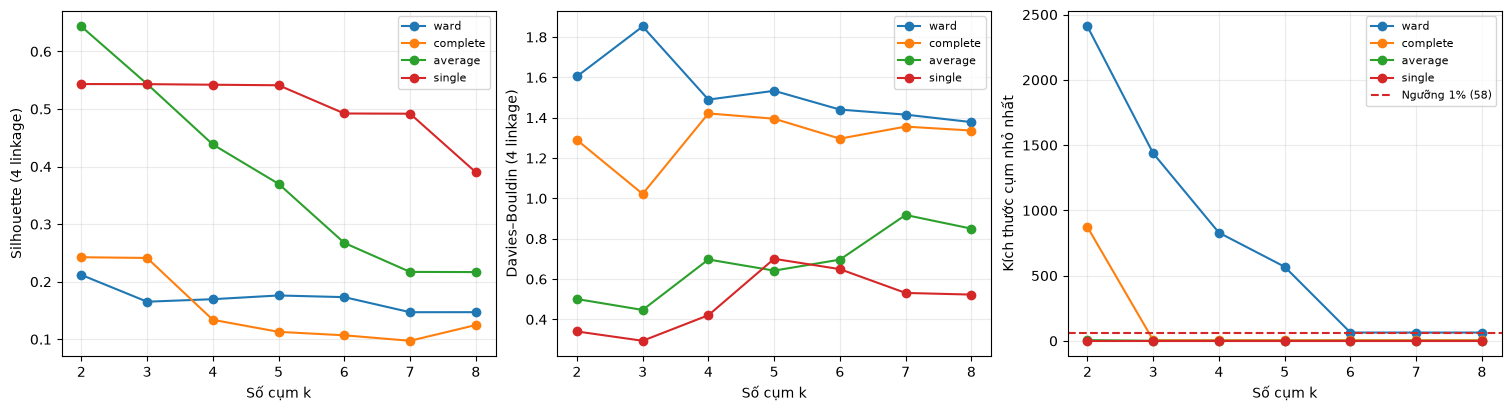

In [2]:
LINKAGES = ["ward", "complete", "average", "single"]
K_VALUES = list(range(2, 9))

trees = {}
labels_by_cut = {}
rows = []

for method in LINKAGES:
    tree = linkage(X, method=method, metric="euclidean")
    trees[method] = tree
    for k, labels in zip(K_VALUES, cut_tree(tree, n_clusters=K_VALUES).T):
        labels_by_cut[method, k] = labels
        rows.append({"linkage": method, "k": k, **evaluate_clustering(X, labels)})

tuning = pd.DataFrame(rows)
min_cluster_size = len(X) // 100

# Bảng tổng hợp kiểm chứng 4 linkage
summary_rows = []
for method in LINKAGES:
    sub = tuning[tuning["linkage"] == method]
    sub_k3 = sub[sub["k"] >= 3]
    valid_all = int((sub["min_cluster_size"] >= min_cluster_size).sum())
    valid_k3 = int((sub_k3["min_cluster_size"] >= min_cluster_size).sum())
    summary_rows.append({
        "linkage": method,
        # Có bao nhiêu lát cắt hợp lệ trên toàn bộ 7 mức (k = 2..8).
        "valid_cuts_all (k>=2)": f"{valid_all}/{len(sub)}",
        # Có bao nhiêu lát cắt hợp lệ trên 6 mức chia chi tiết/mịn (k = 3..8, bỏ mức quá thô k=2).
        "valid_cuts_fine (k>=3)": f"{valid_k3}/{len(sub_k3)}",
        "min_size_at_k3_to_8": int(sub_k3["min_cluster_size"].min()),
        "max_size_at_k3_to_8": int(sub_k3["max_cluster_size"].max()),
        "best_sil_all": round(float(sub["silhouette"].max()), 4),
    })

linkage_summary = pd.DataFrame(summary_rows)
print(f"Ngưỡng cụm không suy biến (>=1%): {min_cluster_size} khách.")
display(linkage_summary)

# Biểu đồ đối chứng 4 linkage
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for method, scores in tuning.groupby("linkage", sort=False):
    axes[0].plot(scores["k"], scores["silhouette"], marker="o", label=method)
    axes[1].plot(scores["k"], scores["davies_bouldin"], marker="o", label=method)
    axes[2].plot(scores["k"], scores["min_cluster_size"], marker="o", label=method)

axes[2].axhline(min_cluster_size, color="tab:red", linestyle="--", label=f"Ngưỡng 1% ({min_cluster_size})")
for ax, title in zip(axes, ["Silhouette (4 linkage)", "Davies–Bouldin (4 linkage)", "Kích thước cụm nhỏ nhất"]):
    ax.set(xlabel="Số cụm k", ylabel=title, xticks=K_VALUES)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.show()

Nhận xét kết quả 4 linkage:
- `average` và `single` có Silhouette cao (`0.54`-`0.64`) nhưng `0/7` lát cắt đạt ngưỡng 1% khách; cụm nhỏ nhất chỉ có 1 đến 6 khách ngoại biên còn lại gom gần hết vào một cụm. Do đó không thể chọn linkage chỉ theo Silhouette thuần.
- `complete` suy biến từ $k \ge 3$ (`min_cluster_size = 5`); mức $k = 2$ đạt ngưỡng nhưng chia khá lệch (`872` vs `4.980`).
- `ward` là linkage duy nhất đạt ngưỡng không suy biến ở cả `7/7` mức $k = 2, \ldots, 8$, nên phần sau sẽ tập trung phân tích sâu trên `ward`.

## 3. Chọn số cụm $k$ trên nhánh `ward`

Trên cây `ward`, chọn $k$ dựa vào 3 yếu tố:
1. Bước nhảy độ cao gộp (`vertical_gap`, `height_ratio`): khoảng cách dọc giữa lần gộp tạo $k$ cụm và lần gộp tiếp theo nhập từ $k$ xuống $k-1$ cụm. Bước nhảy lớn cho thấy các nhánh ở mức $k$ khác biệt rõ.
2. Các chỉ số nội cụm (Silhouette, Davies-Bouldin, Calinski-Harabasz) của riêng `ward`.
3. Độ cân bằng kích thước cụm, tránh cắt quá thô ($k=2$) hoặc tách cụm quá nhỏ.

,k,vertical_gap,height_ratio,silhouette,davies_bouldin,calinski_harabasz,min_cluster_size,max_cluster_size
0,2,33.94,1.450,0.211810,1.604582,1834.252634,2409,3443
1,3,13.50,1.218,0.165265,1.852200,1590.678397,1437,2409
2,4,7.96,1.147,0.169624,1.489784,1463.973220,829,2409
3,5,18.02,1.500,0.176097,1.533385,1388.190578,568,1841
4,6,1.92,1.056,0.173195,1.440380,1231.363807,64,1841
5,7,0.30,1.009,0.147010,1.415275,1125.889668,64,1841
6,8,1.62,1.050,0.147091,1.378220,1057.773553,64,1841


Lát cắt chọn theo lý thuyết nhánh ward: k = 5 (gap=18.02, ratio=1.5x).


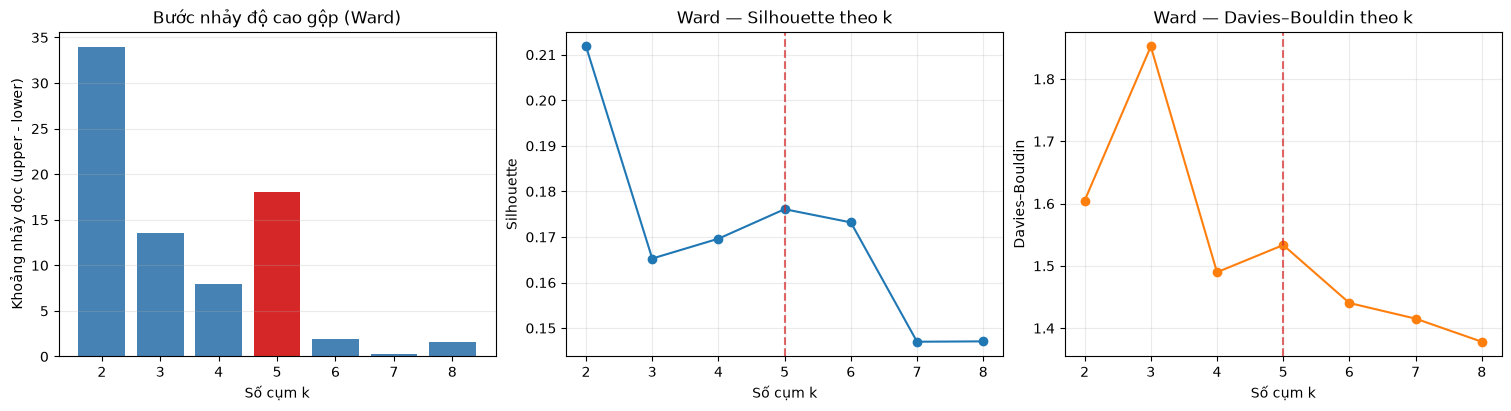

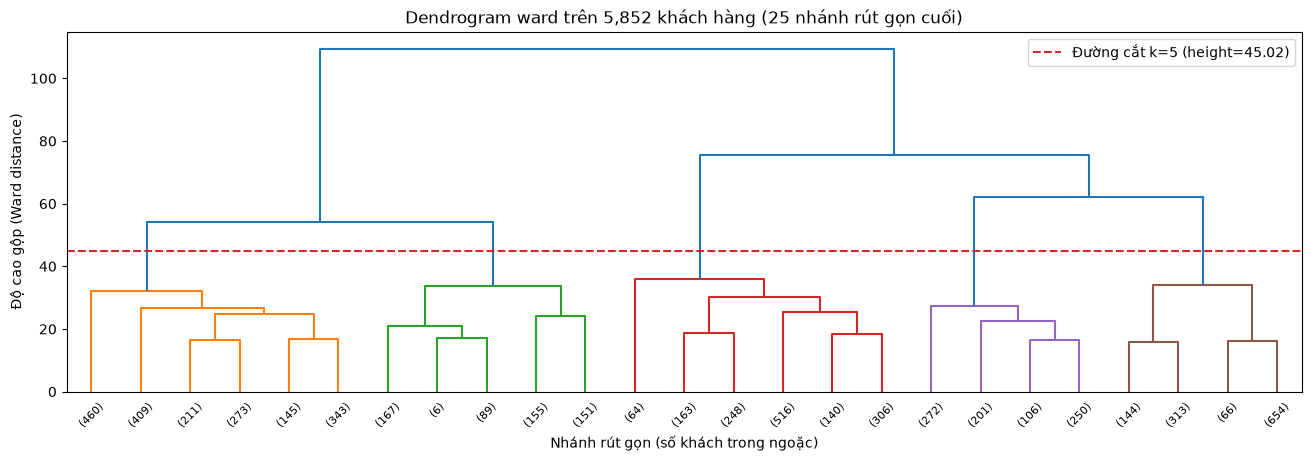

In [3]:
ward_tree = trees["ward"]
gap_rows = []
for k in K_VALUES:
    lower = float(ward_tree[-k, 2])
    upper = float(ward_tree[-k + 1, 2])
    gap = upper - lower
    ratio = upper / lower if lower > 0 else np.nan
    gap_rows.append({
        "k": k,
        "height_lower (k+1->k)": round(lower, 2),
        "height_upper (k->k-1)": round(upper, 2),
        "vertical_gap": round(gap, 2),
        "height_ratio": round(ratio, 3),
    })
ward_gaps = pd.DataFrame(gap_rows)

ward_metrics = tuning[tuning["linkage"] == "ward"].merge(
    ward_gaps[["k", "vertical_gap", "height_ratio"]], on="k", how="left"
)
display(ward_metrics[[
    "k", "vertical_gap", "height_ratio", "silhouette",
    "davies_bouldin", "calinski_harabasz", "min_cluster_size", "max_cluster_size"
]])

# Chọn k độc lập trên nhánh Ward: ưu tiên bước nhảy dọc lớn nhất với k >= 3 và cụm >= 1%
ward_candidates = ward_metrics[
    (ward_metrics["k"] >= 3) & (ward_metrics["min_cluster_size"] >= min_cluster_size)
].sort_values(["vertical_gap", "silhouette"], ascending=[False, False])
auto_k = int(ward_candidates.iloc[0]["k"])
best_method, best_k = ("ward", auto_k) if REVIEW_CUT is None else REVIEW_CUT
if (best_method, best_k) not in labels_by_cut:
    raise ValueError(f"Lát cắt không thuộc lưới tham số: {REVIEW_CUT}")

tuning["selected"] = tuning["linkage"].eq(best_method) & tuning["k"].eq(best_k)
chosen_gap = ward_gaps.loc[ward_gaps["k"] == best_k].iloc[0]
print(f"Lát cắt chọn theo lý thuyết nhánh {best_method}: k = {best_k} "
      f"(gap={chosen_gap['vertical_gap']}, ratio={chosen_gap['height_ratio']}x).")

# Biểu đồ bước nhảy độ cao + chỉ số nội cụm riêng cho Ward
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
axes[0].bar(ward_gaps["k"], ward_gaps["vertical_gap"], color=[
    "tab:red" if k == best_k else "steelblue" for k in ward_gaps["k"]
])
axes[0].set(title="Bước nhảy độ cao gộp (Ward)", xlabel="Số cụm k", ylabel="Khoảng nhảy dọc (upper - lower)", xticks=ward_gaps["k"])
axes[0].grid(axis="y", alpha=0.25)

axes[1].plot(ward_metrics["k"], ward_metrics["silhouette"], marker="o", color="tab:blue", label="Silhouette")
axes[1].axvline(best_k, color="tab:red", linestyle="--", alpha=0.7)
axes[1].set(title="Ward — Silhouette theo k", xlabel="Số cụm k", ylabel="Silhouette", xticks=K_VALUES)
axes[1].grid(alpha=0.25)

axes[2].plot(ward_metrics["k"], ward_metrics["davies_bouldin"], marker="o", color="tab:orange", label="Davies–Bouldin")
axes[2].axvline(best_k, color="tab:red", linestyle="--", alpha=0.7)
axes[2].set(title="Ward — Davies–Bouldin theo k", xlabel="Số cụm k", ylabel="Davies–Bouldin", xticks=K_VALUES)
axes[2].grid(alpha=0.25)
plt.show()

# Dendrogram của nhánh đã chọn
tree = trees[best_method]
lower, upper = tree[-best_k, 2], tree[-best_k + 1, 2]
cut_height = (lower + upper) / 2
fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
dendrogram(tree, ax=ax, truncate_mode="lastp", p=min(25, len(X)),
           color_threshold=cut_height, leaf_font_size=8)
line_label = f"Đường cắt k={best_k} (height={cut_height:.2f})" if lower < upper else "Hai lần gộp cùng độ cao"
ax.axhline(cut_height, color="tab:red", linestyle="--", label=line_label)
ax.set(title=f"Dendrogram {best_method} trên {len(X):,} khách hàng (25 nhánh rút gọn cuối)",
       xlabel="Nhánh rút gọn (số khách trong ngoặc)", ylabel="Độ cao gộp (Ward distance)")
ax.legend()
plt.show()

Cách chọn lát cắt trên `ward`:
- Lọc các mức $k \ge 3$ và mọi cụm đạt tối thiểu 1% tổng số khách.
- Ưu tiên mức có bước nhảy dọc (`vertical_gap`) lớn nhất trên Dendrogram, sau đó đối chiếu thêm Silhouette, Davies-Bouldin và kích thước cụm.
- Có thể chỉnh tay `REVIEW_CUT` ở đầu notebook nếu muốn thử lát cắt khác.

## 4. Xuất nhãn cho nhóm đánh giá

Lưu bảng tinh chỉnh 4 linkage vào `clustering/results/tuning_hierarchical.csv` (đánh dấu `selected=True` ở cấu hình chọn) và cập nhật cột `hierarchical` trong `clustering/results/labels.csv`.

In [4]:
final_labels = labels_by_cut[best_method, best_k]
display(pd.Series(final_labels, name="Số khách").value_counts().sort_index())
save_tuning_results(tuning, "tuning_hierarchical.csv", results_dir)
_ = save_cluster_labels(customer_ids, "hierarchical", final_labels, results_dir / "labels.csv")

Số khách
0     568
1    1841
2    1177
3    1437
4     829
Name: count, dtype: int64

[SAVED] Đã lưu bảng tinh chỉnh -> clustering/results/tuning_hierarchical.csv
[SAVED] Đã cập nhật cột 'hierarchical' -> clustering/results/labels.csv
